# 📊 Retail Sales & Customer Behavior Analytics
**Author:** Sendy Tegar Mahendra

**Objective:** Melakukan **Data Cleaning**, Feature Engineering, dan Exploratory Data Analysis (EDA) pada dataset SuperStore Global untuk mengidentifikasi tren penjualan, profitabilitas kategori, dan efisiensi pengiriman. Dataset bersih yang dihasilkan dari **pipeline** ini akan digunakan untuk pembuatan *Interactive Dashboard* pendukung keputusan strategis.

In [ ]:
# 1. Import Library
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style grafik
sns.set_theme(style="whitegrid")

# 2. Load Dataset
df = pd.read_csv('SuperStoreOrders.csv')

# Tampilkan 5 baris pertama untuk inspeksi awal
display(df.head())

,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,...,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year
0,AG-2011-2040,1/1/2011,6/1/2011,Standard Class,Toby Braunhardt,Consumer,Constantine,Algeria,Africa,Africa,...,Office Supplies,Storage,"Tenex Lockers, Blue",408,2,0.0,106.140,35.46,Medium,2011
1,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,Office Supplies,Supplies,"Acme Trimmer, High Speed",120,3,0.1,36.036,9.72,Medium,2011
2,HU-2011-1220,1/1/2011,5/1/2011,Second Class,Annie Thurman,Consumer,Budapest,Hungary,EMEA,EMEA,...,Office Supplies,Storage,"Tenex Box, Single Width",66,4,0.0,29.640,8.17,High,2011
3,IT-2011-3647632,1/1/2011,5/1/2011,Second Class,Eugene Moren,Home Office,Stockholm,Sweden,EU,North,...,Office Supplies,Paper,"Enermax Note Cards, Premium",45,3,0.5,-26.055,4.82,High,2011
4,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,Furniture,Furnishings,"Eldon Light Bulb, Duo Pack",114,5,0.1,37.770,4.70,Medium,2011


In [ ]:
# 3. Pengecekan Informasi Dataset (Tipe Data & Missing Values)
print("=== INFO DATASET ===")
df.info()

print("\n=== PENGECEKAN DATA KOSONG (MISSING VALUES) ===")
print(df.isnull().sum())

print("\n=== PENGECEKAN DATA DUPLIKAT ===")
print(f"Jumlah baris duplikat: {df.duplicated().sum()}")

=== INFO DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        51290 non-null  object 
 1   order_date      51290 non-null  object 
 2   ship_date       51290 non-null  object 
 3   ship_mode       51290 non-null  object 
 4   customer_name   51290 non-null  object 
 5   segment         51290 non-null  object 
 6   state           51290 non-null  object 
 7   country         51290 non-null  object 
 8   market          51290 non-null  object 
 9   region          51290 non-null  object 
 10  product_id      51290 non-null  object 
 11  category        51290 non-null  object 
 12  sub_category    51290 non-null  object 
 13  product_name    51290 non-null  object 
 14  sales           51290 non-null  object 
 15  quantity        51290 non-null  int64  
 16  discount        51290 non-null  float64
 17  profit    

In [ ]:
# Muat ulang data mentah
df = pd.read_csv('SuperStoreOrders.csv')

# 4A. DATA CLEANING: Mengubah tipe data 'sales' dari string/teks ke numerik (float)
df['sales'] = df['sales'].astype(str).str.replace(',', '').astype(float)

# 4B. DATA CLEANING: Standarisasi format Tanggal (Datetime)
for col in ['order_date', 'ship_date']:
    df[col] = pd.to_datetime(df[col].str.replace('-', '/', regex=False), format='%d/%m/%Y', errors='coerce')

assert df[['order_date', 'ship_date']].isna().sum().sum() == 0, "Ada tanggal yang gagal di-parse"

# 4C. FEATURE ENGINEERING
df['delivery_time_days'] = (df['ship_date'] - df['order_date']).dt.days
df['order_month_year'] = df['order_date'].dt.to_period('M')

print("Data Cleaning & Feature Engineering Selesai. Tipe data saat ini:")
print(df[['sales', 'order_date', 'ship_date', 'delivery_time_days']].dtypes)
print("\nRata-rata waktu pengiriman per Ship Mode (hari):")
print(df.groupby('ship_mode')['delivery_time_days'].mean().round(2))

Data Cleaning & Feature Engineering Selesai. Tipe data saat ini:
sales                        float64
order_date            datetime64[ns]
ship_date             datetime64[ns]
delivery_time_days             int64
dtype: object

Rata-rata waktu pengiriman per Ship Mode (hari):
ship_mode
First Class       2.18
Same Day          0.04
Second Class      3.23
Standard Class    5.00
Name: delivery_time_days, dtype: float64


/tmp/ipykernel_671/3168628209.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_performance, x='sales', y='category', palette='viridis')


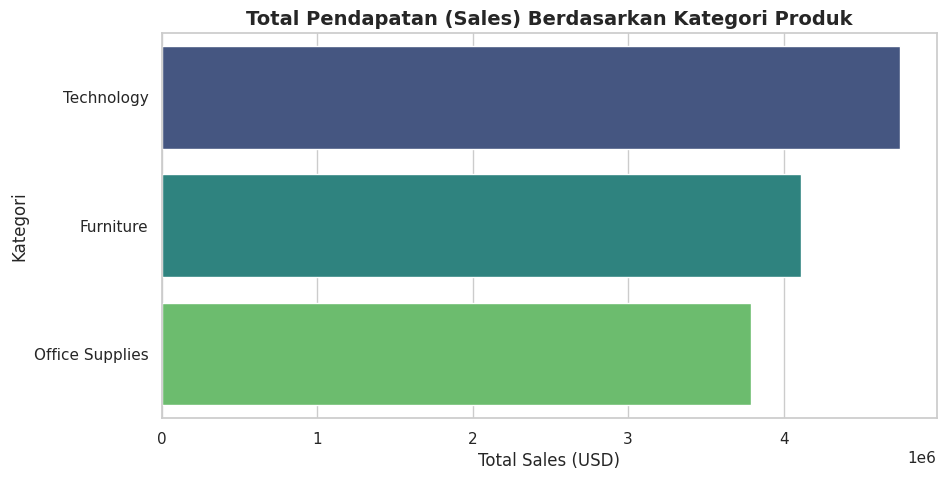

,category,sales,profit
2,Technology,4744691.0,663778.73318
0,Furniture,4110884.0,286782.25380
1,Office Supplies,3787330.0,518473.83430


In [ ]:
# 5. Analisis Performa Kategori Produk (Total Sales & Profit)
category_performance = df.groupby('category')[['sales', 'profit']].sum().reset_index()
category_performance = category_performance.sort_values(by='sales', ascending=False)

# Membuat Visualisasi Bar Chart
plt.figure(figsize=(10, 5))
sns.barplot(data=category_performance, x='sales', y='category', palette='viridis')
plt.title('Total Pendapatan (Sales) Berdasarkan Kategori Produk', fontsize=14, fontweight='bold')
plt.xlabel('Total Sales (USD)', fontsize=12)
plt.ylabel('Kategori', fontsize=12)
plt.show()

# Menampilkan tabel agregasi
display(category_performance)

In [ ]:
# 6. Simpan dataset yang sudah bersih untuk dihubungkan ke Tableau / Looker Studio
df_export = df.drop(columns=['order_month_year'], errors='ignore')

clean_filename = 'Cleaned_SuperStoreOrders.csv'
df_export.to_csv(clean_filename, index=False)

print(f"Dataset bersih berhasil disimpan sebagai '{clean_filename}'")

Dataset bersih berhasil disimpan sebagai 'Cleaned_SuperStoreOrders.csv'
